# 01 · Veri İnceleme ve Öznitelik Değerlendirmesi

**Amaç:** Modellemeye başlamadan önce 36 sütunun her birini tanımak ve şu sorulara cevap vermek:

1. Her öznitelik ne anlatıyor, hangi grupta?
2. Nerede eksik değer var? Eksiklik gerçek mi, yapısal mı, gizli mi?
3. Hangi sütunlar gereksiz (sabit, tekrar eden, başka sütundan türetilmiş)?
4. Mantıksal tutarsızlık, aykırı değer, tekrar eden satır var mı?
5. Hangi sütunlar hedef, hangileri **asla** girdi olarak kullanılmamalı?

Sonunda her sütun için bir **ön işleme kararı tablosu** çıkarıyoruz (`results/tables/oznitelik_kararlari.csv`).

> Bu notebook veriyi **değiştirmez**; sadece inceler. Asıl temizleme ve imputasyon, sızıntı olmaması için 03'te `Pipeline` içinde yapılacak.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", font_scale=0.9)

FIG = Path("../results/figures")
TAB = Path("../results/tables")

# '?' işaretleri eksik değer (NaN) olarak okunur
df = pd.read_csv("../data/risk_factors_cervical_cancer.csv", na_values="?")
print("Boyut:", df.shape)

Boyut: (858, 36)


## 1. Öznitelik grupları

36 sütun anlam olarak 7 gruba ayrılıyor. Gruplamak önemli, çünkü eksiklik de bu gruplar halinde ortaya çıkıyor.

In [2]:
TARGETS = ["Hinselmann", "Schiller", "Citology", "Biopsy"]
STD_TYPES = [c for c in df.columns if c.startswith("STDs:") and "Number" not in c and "Time" not in c]

groups = {
    "Demografi / cinsel öykü": ["Age", "Number of sexual partners", "First sexual intercourse", "Num of pregnancies"],
    "Sigara":                  ["Smokes", "Smokes (years)", "Smokes (packs/year)"],
    "Hormonal kontraseptif":   ["Hormonal Contraceptives", "Hormonal Contraceptives (years)"],
    "RİA (IUD)":               ["IUD", "IUD (years)"],
    "Cinsel yolla bulaşan hastalık (CYBH)": ["STDs", "STDs (number)"] + STD_TYPES
                               + ["STDs: Number of diagnosis", "STDs: Time since first diagnosis", "STDs: Time since last diagnosis"],
    "Önceki tanılar (Dx)":     ["Dx:Cancer", "Dx:CIN", "Dx:HPV", "Dx"],
    "Hedef / tarama testleri": TARGETS,
}
group_of = {c: g for g, cols in groups.items() for c in cols}
assert len(group_of) == df.shape[1], "Her sütun tam olarak bir gruba ait olmalı"

for g, cols in groups.items():
    print(f"{g} ({len(cols)}): {', '.join(cols)}")

Demografi / cinsel öykü (4): Age, Number of sexual partners, First sexual intercourse, Num of pregnancies
Sigara (3): Smokes, Smokes (years), Smokes (packs/year)
Hormonal kontraseptif (2): Hormonal Contraceptives, Hormonal Contraceptives (years)
RİA (IUD) (2): IUD, IUD (years)
Cinsel yolla bulaşan hastalık (CYBH) (17): STDs, STDs (number), STDs:condylomatosis, STDs:cervical condylomatosis, STDs:vaginal condylomatosis, STDs:vulvo-perineal condylomatosis, STDs:syphilis, STDs:pelvic inflammatory disease, STDs:genital herpes, STDs:molluscum contagiosum, STDs:AIDS, STDs:HIV, STDs:Hepatitis B, STDs:HPV, STDs: Number of diagnosis, STDs: Time since first diagnosis, STDs: Time since last diagnosis
Önceki tanılar (Dx) (4): Dx:Cancer, Dx:CIN, Dx:HPV, Dx
Hedef / tarama testleri (4): Hinselmann, Schiller, Citology, Biopsy


## 2. Sütun profili: tip, eksik, tekil değer, aralık

In [3]:
profile = pd.DataFrame({
    "grup": [group_of[c] for c in df.columns],
    "eksik": df.isna().sum(),
    "eksik_%": (df.isna().mean() * 100).round(1),
    "tekil": df.nunique(),
    "min": df.min(),
    "medyan": df.median(),
    "max": df.max(),
})
# İkili (0/1) sütunlarda kaç tane 1 var
profile["1_sayısı"] = [int((df[c] == 1).sum()) if df[c].nunique() <= 2 else np.nan for c in df.columns]
profile

,grup,eksik,eksik_%,tekil,min,medyan,max,1_sayısı
Age,Demografi / cinsel öykü,0,0.0,44,13.0,25.0,84.0,NaN
Number of sexual partners,Demografi / cinsel öykü,26,3.0,12,1.0,2.0,28.0,NaN
First sexual intercourse,Demografi / cinsel öykü,7,0.8,21,10.0,17.0,32.0,NaN
Num of pregnancies,Demografi / cinsel öykü,56,6.5,11,0.0,2.0,11.0,NaN
Smokes,Sigara,13,1.5,2,0.0,0.0,1.0,123.0
Smokes (years),Sigara,13,1.5,30,0.0,0.0,37.0,NaN
Smokes (packs/year),Sigara,13,1.5,62,0.0,0.0,37.0,NaN
Hormonal Contraceptives,Hormonal kontraseptif,108,12.6,2,0.0,1.0,1.0,481.0
Hormonal Contraceptives (years),Hormonal kontraseptif,108,12.6,40,0.0,0.5,30.0,NaN
IUD,RİA (IUD),117,13.6,2,0.0,0.0,1.0,83.0


**Okuma notu:** Gördüğün `float` sütunlar aslında çoğunlukla 0/1 (ikili) ya da sayım değişkenleri. pandas onları `float` okuyor, çünkü içlerinde `NaN` var (tam sayı tipi NaN tutamaz).

## 3. Eksik veri: genel tablo

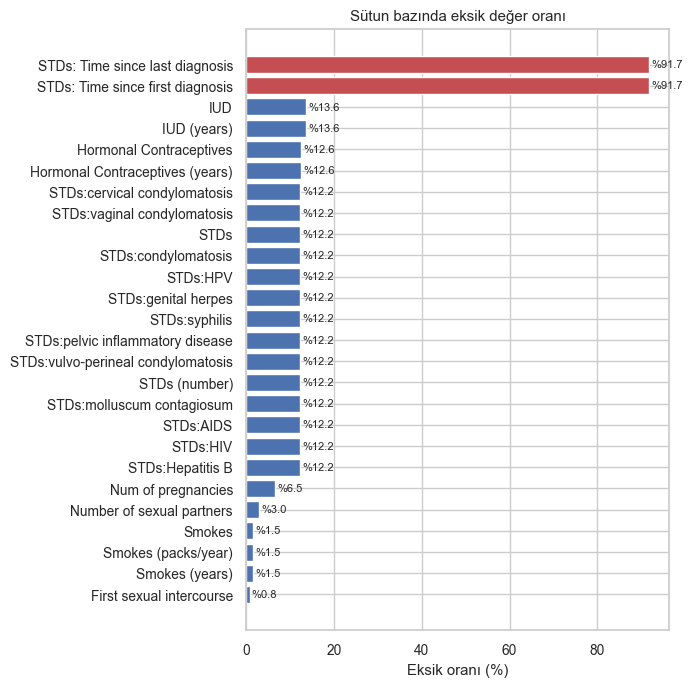

Hiç eksiği olmayan hasta: 59 / 858
Time since... sütunları hariç hiç eksiği olmayan hasta: 668


In [4]:
miss = df.isna().mean().mul(100).sort_values()
miss = miss[miss > 0]

fig, ax = plt.subplots(figsize=(7, 7))
colors = [sns.color_palette()[3] if "Time since" in c else sns.color_palette()[0] for c in miss.index]
ax.barh(miss.index, miss.values, color=colors)
ax.set_xlabel("Eksik oranı (%)")
ax.set_title("Sütun bazında eksik değer oranı")
for i, v in enumerate(miss.values):
    ax.text(v + 0.5, i, f"%{v:.1f}", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "01_eksik_oran.png", dpi=150)
plt.show()

print("Hiç eksiği olmayan hasta:", df.notna().all(axis=1).sum(), "/", len(df))
print("Time since... sütunları hariç hiç eksiği olmayan hasta:",
      df.drop(columns=["STDs: Time since first diagnosis", "STDs: Time since last diagnosis"]).notna().all(axis=1).sum())

Eksiklik dağınık değil, **bloklar halinde**. Aşağıdaki matriste her satır bir hasta, her sütun bir öznitelik; siyah hücreler eksik. Hastalar eksiklik desenine göre sıralandı.

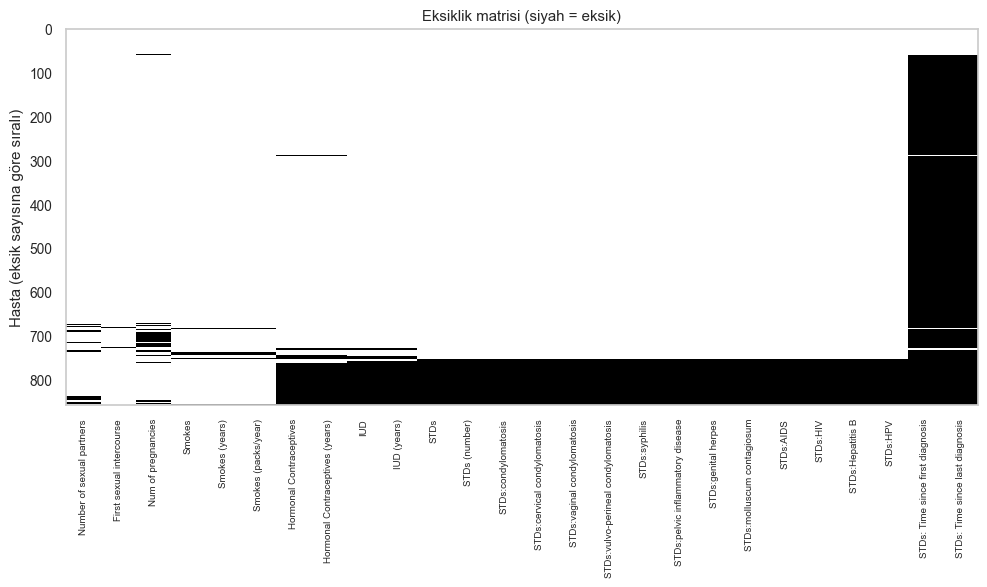

In [5]:
cols_with_miss = [c for c in df.columns if df[c].isna().any()]
order = df[cols_with_miss].isna().sum(axis=1).sort_values(kind="stable").index

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(df.loc[order, cols_with_miss].isna().values, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_xticks(range(len(cols_with_miss)))
ax.set_xticklabels(cols_with_miss, rotation=90, fontsize=7)
ax.grid(False)
ax.set_ylabel("Hasta (eksik sayısına göre sıralı)")
ax.set_title("Eksiklik matrisi (siyah = eksik)")
plt.tight_layout()
plt.savefig(FIG / "01_eksiklik_matrisi.png", dpi=150)
plt.show()

### 3a. Eksiklik desenleri

Her grubun "temsilci" sütununa bakarak kaç farklı eksiklik deseni olduğunu sayalım.

In [6]:
rep = {"Sigara": "Smokes", "HK": "Hormonal Contraceptives", "RİA": "IUD", "CYBH": "STDs",
       "Gebelik": "Num of pregnancies", "Partner": "Number of sexual partners", "İlk ilişki": "First sexual intercourse"}
M = pd.DataFrame({k: df[v].isna() for k, v in rep.items()})
patterns = M.value_counts().rename("hasta_sayısı").reset_index()
patterns.replace({True: "EKSİK", False: "·"}).head(10)

,Sigara,HK,RİA,CYBH,Gebelik,Partner,İlk ilişki,hasta_sayısı
0,·,·,·,·,·,·,·,668
1,·,EKSİK,EKSİK,EKSİK,·,·,·,75
2,·,·,·,·,EKSİK,·,·,39
3,·,·,·,·,·,EKSİK,·,11
4,·,EKSİK,EKSİK,EKSİK,·,EKSİK,·,10
5,·,EKSİK,EKSİK,·,·,·,·,9
6,EKSİK,·,·,·,·,·,·,8
7,·,·,EKSİK,·,EKSİK,·,·,5
8,·,EKSİK,EKSİK,EKSİK,EKSİK,·,·,5
9,·,·,·,·,·,·,EKSİK,5


In [7]:
s = M["CYBH"]
print(f"CYBH soruları eksik olan {s.sum()} hastanın:")
print(f"  hormonal kontraseptif sorusu da eksik: %{M['HK'][s].mean()*100:.0f}")
print(f"  RİA sorusu da eksik:                   %{M['RİA'][s].mean()*100:.0f}")

CYBH soruları eksik olan 105 hastanın:
  hormonal kontraseptif sorusu da eksik: %90
  RİA sorusu da eksik:                   %96


**Yorum:** Hassas sorular (kontraseptif, RİA, CYBH) **birlikte** cevapsız bırakılmış. Bu, sütunların tek tek rastgele boşaldığını değil, hastanın bir soru bloğunu bütünüyle atladığını gösteriyor. Bunun mekanizmasını (MCAR/MAR/MNAR) 02'de ayrıntılı test edeceğiz.

### 3b. Eksiklik hedefle ilişkili mi? (ön bakış)

In [8]:
rows = []
for k, v in rep.items():
    m = df[v].isna()
    rows.append({"grup": k, "eksik_n": int(m.sum()),
                 "biyopsi+_% (eksik)": round(df.loc[m, "Biopsy"].mean() * 100, 1),
                 "biyopsi+_% (dolu)": round(df.loc[~m, "Biopsy"].mean() * 100, 1)})
pd.DataFrame(rows)

,grup,eksik_n,biyopsi+_% (eksik),biyopsi+_% (dolu)
0,Sigara,13,7.7,6.4
1,HK,108,0.0,7.3
2,RİA,117,2.6,7.0
3,CYBH,105,1.9,7.0
4,Gebelik,56,12.5,6.0
5,Partner,26,3.8,6.5
6,İlk ilişki,7,0.0,6.5


Örneğin hormonal kontraseptif sorusunu boş bırakan 108 hastanın **hiçbirinde** biyopsi pozitif değil; cevaplayanlarda oran %7.3. Yani "boş bırakmak" tek başına bilgi taşıyor. Bu, projenin ana sorusunun ilk ipucu. Pozitif sayıları çok küçük olduğu için istatistiksel testi 02'de yapacağız.

### 3c. Üç farklı türde "eksiklik"

Bu veri setinde eksiklik üç farklı biçimde karşımıza çıkıyor ve **her biri farklı ele alınmalı**:

| Tür | Sütun | Açıklama |
|---|---|---|
| **Gerçek eksik** | Sigara, HK, RİA, CYBH, gebelik, partner, ilk ilişki | Hasta cevaplamamış → imputasyon + eksiklik göstergesi |
| **Yapısal eksik** | `STDs: Time since first/last diagnosis` | CYBH tanısı yoksa "tanıdan bu yana geçen süre" **tanımsız**. Bilgi eksik değil, soru anlamsız. |
| **Gizli eksik** | `STDs: Number of diagnosis` | Eksik görünmüyor ama CYBH soruları cevapsız olan hastalarda `0` yazılmış |

In [9]:
# Yapısal eksik: süre bilgisi yalnızca tanı almış hastalarda var mı?
has_time = df["STDs: Time since first diagnosis"].notna()
has_dx = df["STDs: Number of diagnosis"] > 0
print("Süre bilgisi var  ⇔  tanı sayısı > 0  uyumu: %", round((has_time == has_dx).mean() * 100, 1))

# Gizli eksik: CYBH soruları boşken 'Number of diagnosis' ne yazıyor?
print("\nCYBH eksik olan hastalarda 'STDs: Number of diagnosis' değerleri:")
print(df.loc[df["STDs"].isna(), "STDs: Number of diagnosis"].value_counts())

Süre bilgisi var  ⇔  tanı sayısı > 0  uyumu: % 100.0

CYBH eksik olan hastalarda 'STDs: Number of diagnosis' değerleri:
STDs: Number of diagnosis
0    105
Name: count, dtype: int64


**Sonuç:** CYBH sorularını cevaplamayan 105 hastanın hepsinde `STDs: Number of diagnosis = 0`. Bu "tanı yok" değil, "bilinmiyor" demek. Bu sütunu olduğu gibi kullanırsak model "bilinmiyor"u "tanı yok" sanır. Bu yüzden ya o 105 hasta için `NaN` yapılmalı ya da sütun çıkarılmalı.

## 4. Gereksiz (bilgi taşımayan veya tekrar eden) sütunlar

### 4a. Sabit sütunlar

In [10]:
constant = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]
print("Tek değer alan sütunlar:", constant)
for c in constant:
    print(f"  {c}: {df[c].value_counts(dropna=False).to_dict()}")

Tek değer alan sütunlar: ['STDs:cervical condylomatosis', 'STDs:AIDS']
  STDs:cervical condylomatosis: {0.0: 753, nan: 105}
  STDs:AIDS: {0.0: 753, nan: 105}


Hiç kimsede pozitif olmayan bir sütun modele hiçbir bilgi veremez → **çıkarılmalı**.

Ayrıca çok nadir olanlar da var: aşağıdaki sütunlarda yalnızca **1 hasta** pozitif. Tek bir örnekten model bir şey öğrenemez; bunlar da tek tek kullanılmak yerine çıkarılmalı ya da birleştirilmeli.

In [11]:
rare = profile[(profile["tekil"] == 2) & (profile["1_sayısı"] <= 5) & (profile["grup"] != "Hedef / tarama testleri")]
rare[["grup", "1_sayısı", "eksik"]]

,grup,1_sayısı,eksik
STDs:vaginal condylomatosis,Cinsel yolla bulaşan hastalık (CYBH),4.0,105
STDs:pelvic inflammatory disease,Cinsel yolla bulaşan hastalık (CYBH),1.0,105
STDs:genital herpes,Cinsel yolla bulaşan hastalık (CYBH),1.0,105
STDs:molluscum contagiosum,Cinsel yolla bulaşan hastalık (CYBH),1.0,105
STDs:Hepatitis B,Cinsel yolla bulaşan hastalık (CYBH),1.0,105
STDs:HPV,Cinsel yolla bulaşan hastalık (CYBH),2.0,105


### 4b. Türetilmiş (birbirinden hesaplanabilen) sütunlar

Bazı sütunlar başka sütunların özeti. Bunu doğrulayalım:

In [12]:
def check(name, cond, mask=None):
    m = mask if mask is not None else pd.Series(True, index=df.index)
    print(f"{name:<55} uyum: %{cond[m].mean()*100:.1f}")

known = df["STDs"].notna()
check("Smokes = 1  ⇔  Smokes (years) > 0", (df["Smokes"] == 1) == (df["Smokes (years)"] > 0), df["Smokes"].notna())
check("HC = 1  ⇔  HC (years) > 0", (df["Hormonal Contraceptives"] == 1) == (df["Hormonal Contraceptives (years)"] > 0), df["Hormonal Contraceptives"].notna())
check("IUD = 1  ⇔  IUD (years) > 0", (df["IUD"] == 1) == (df["IUD (years)"] > 0), df["IUD"].notna())
check("STDs = 1  ⇔  STDs (number) > 0", (df["STDs"] == 1) == (df["STDs (number)"] > 0), known)
check("STDs (number) = alt tür sütunlarının toplamı", df["STDs (number)"] == df[STD_TYPES].sum(axis=1), known)
check("Dx = Dx:Cancer veya Dx:CIN veya Dx:HPV", df["Dx"] == df[["Dx:Cancer", "Dx:CIN", "Dx:HPV"]].max(axis=1))

Smokes = 1  ⇔  Smokes (years) > 0                       uyum: %100.0
HC = 1  ⇔  HC (years) > 0                               uyum: %100.0
IUD = 1  ⇔  IUD (years) > 0                             uyum: %100.0
STDs = 1  ⇔  STDs (number) > 0                          uyum: %100.0
STDs (number) = alt tür sütunlarının toplamı            uyum: %100.0
Dx = Dx:Cancer veya Dx:CIN veya Dx:HPV                  uyum: %99.4


**Yorum:**
- `Smokes`, `Hormonal Contraceptives`, `IUD`, `STDs` ikili sütunları, yanlarındaki "süre/sayı" sütunlarından **birebir** türetilebiliyor. Yani aynı bilgiyi iki kez taşıyorlar. Doğrusal modellerde bu çoklu bağlantı (multicollinearity) sorunu yaratır; ağaç modellerinde zarar vermez ama SHAP katkısını iki sütuna bölerek yorumu zorlaştırır. → Birini tutmak yeterli.
- `Dx`, alt sütunlarının "veya"sı olmalı ama **%0.6 uyumsuzluk** var (aşağıda).

### 4c. Yüksek korelasyonlu çiftler

In [13]:
X_only = df.drop(columns=TARGETS)
corr = X_only.corr().abs()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename("|r|").reset_index()
             .query("`|r|` > 0.8").sort_values("|r|", ascending=False))
pairs.round(3)

,level_0,level_1,|r|
298,STDs:condylomatosis,STDs:vulvo-perineal condylomatosis,0.988
418,STDs: Time since first diagnosis,STDs: Time since last diagnosis,0.931
264,STDs,STDs (number),0.919
275,STDs,STDs: Number of diagnosis,0.907
280,STDs (number),STDs:condylomatosis,0.900
290,STDs (number),STDs: Number of diagnosis,0.897
282,STDs (number),STDs:vulvo-perineal condylomatosis,0.891
428,Dx:Cancer,Dx:HPV,0.887


In [14]:
print("Dx:Cancer ile Dx:HPV çapraz tablo:")
pd.crosstab(df["Dx:Cancer"], df["Dx:HPV"])

Dx:Cancer ile Dx:HPV çapraz tablo:


Dx:HPV,0,1
Dx:Cancer,,
0,838,2
1,2,16


- `STDs:condylomatosis` ve `STDs:vulvo-perineal condylomatosis` neredeyse aynı (r ≈ 0.99): vulvo-perineal, kondilomatozun alt türü.
- `Dx:Cancer` ile `Dx:HPV` 18 hastanın 16'sında birlikte 1. Bu ikisi neredeyse aynı hastaları işaret ediyor.

## 5. Mantıksal tutarsızlıklar

In [15]:
bad_age = df[df["First sexual intercourse"] > df["Age"]]
print("İlk cinsel ilişki yaşı > şimdiki yaş:")
display(bad_age[["Age", "First sexual intercourse"]])

bad_dx = df[df["Dx"] != df[["Dx:Cancer", "Dx:CIN", "Dx:HPV"]].max(axis=1)]
print("Dx = 0 ama alt tanılardan biri 1:")
display(bad_dx[["Dx", "Dx:Cancer", "Dx:CIN", "Dx:HPV"]])

smokers = df["Smokes"] == 1
print(f"Sigara içenlerde 'yıl' ile 'paket/yıl' birebir aynı: {(df.loc[smokers, 'Smokes (years)'] == df.loc[smokers, 'Smokes (packs/year)']).sum()} / {smokers.sum()}")

İlk cinsel ilişki yaşı > şimdiki yaş:


,Age,First sexual intercourse
312,23,27.0
812,14,16.0


Dx = 0 ama alt tanılardan biri 1:


,Dx,Dx:Cancer,Dx:CIN,Dx:HPV
3,0,1,0,1
23,0,1,0,1
64,0,1,0,1
372,0,0,0,1
849,0,1,0,1


Sigara içenlerde 'yıl' ile 'paket/yıl' birebir aynı: 14 / 123


- **2 hastada** ilk cinsel ilişki yaşı şimdiki yaştan büyük. Bu imkânsız, veri girişi hatası. → İlgili değer `NaN` yapılmalı.
- **5 hastada** `Dx = 0` ama `Dx:Cancer` veya `Dx:HPV` = 1. → `Dx` sütunu güvenilir değil; zaten alt sütunlardan türetilebildiği için çıkarılması en temizi.
- Sigara içen bazı hastalarda "yıl" ve "paket/yıl" tam olarak aynı (örneğin 37 ve 37). Bu tek başına hata değil ama şüpheli; aykırı değerlerle birlikte not ediyoruz.

## 6. Sürekli değişkenlerin dağılımı ve aykırı değerler

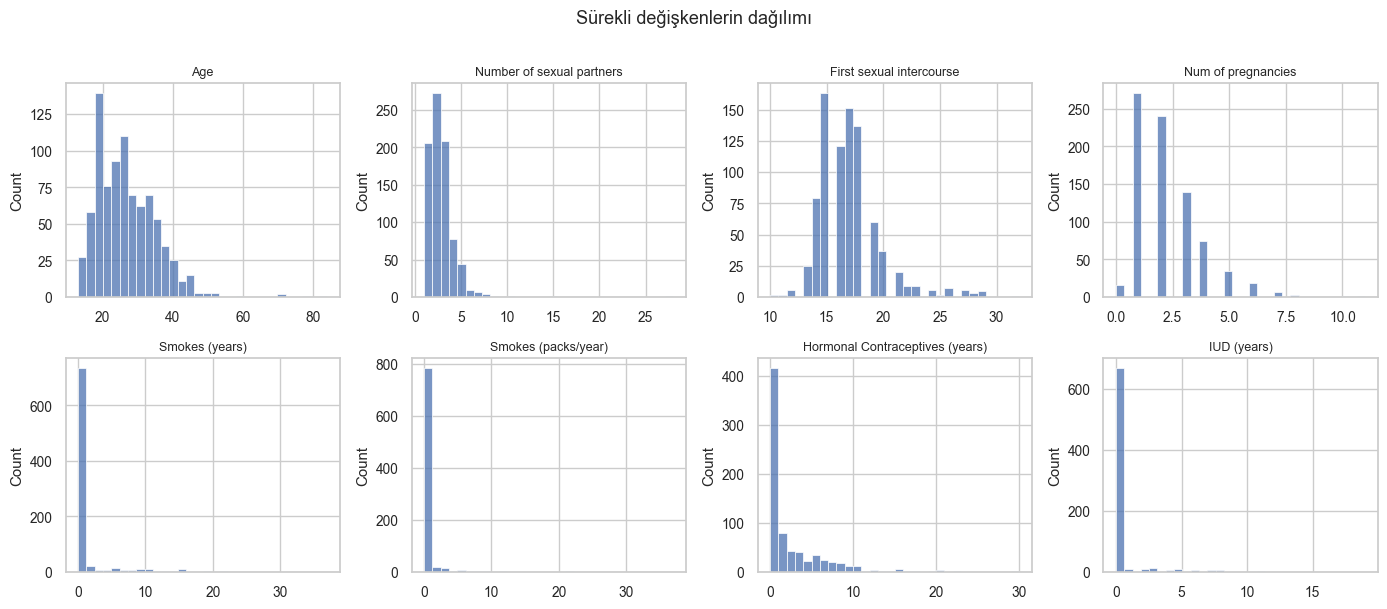

In [16]:
num_cols = ["Age", "Number of sexual partners", "First sexual intercourse", "Num of pregnancies",
            "Smokes (years)", "Smokes (packs/year)", "Hormonal Contraceptives (years)", "IUD (years)"]

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axes.flat, num_cols):
    sns.histplot(df[c].dropna(), ax=ax, bins=30)
    ax.set_title(c, fontsize=9)
    ax.set_xlabel("")
plt.suptitle("Sürekli değişkenlerin dağılımı", y=1.01)
plt.tight_layout()
plt.savefig(FIG / "01_dagilimlar.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
df[num_cols].describe(percentiles=[.5, .95, .99]).T.round(1)

,count,mean,std,min,50%,95%,99%,max
Age,858.0,26.8,8.5,13.0,25.0,41.0,49.4,84.0
Number of sexual partners,832.0,2.5,1.7,1.0,2.0,5.0,7.0,28.0
First sexual intercourse,851.0,17.0,2.8,10.0,17.0,22.0,27.5,32.0
Num of pregnancies,802.0,2.3,1.4,0.0,2.0,5.0,7.0,11.0
Smokes (years),845.0,1.2,4.1,0.0,0.0,9.8,19.6,37.0
Smokes (packs/year),845.0,0.5,2.2,0.0,0.0,2.5,9.0,37.0
Hormonal Contraceptives (years),750.0,2.3,3.8,0.0,0.5,9.5,18.0,30.0
IUD (years),741.0,0.5,1.9,0.0,0.0,4.0,9.6,19.0


In [18]:
print("Sıfırdan farklı değer oranı (sağa çarpıklık kontrolü):")
for c in ["Smokes (years)", "Smokes (packs/year)", "Hormonal Contraceptives (years)", "IUD (years)"]:
    print(f"  {c:<35} %{(df[c] > 0).mean()*100:.0f}")

print("\nUç değerler:")
print("  Yaş < 15:", (df["Age"] < 15).sum(), "  |  Yaş > 60:", (df["Age"] > 60).sum())
print("  Partner sayısı > 10:", (df["Number of sexual partners"] > 10).sum())
print("  Gebelik sayısı > 8:", (df["Num of pregnancies"] > 8).sum())

Sıfırdan farklı değer oranı (sağa çarpıklık kontrolü):
  Smokes (years)                      %14
  Smokes (packs/year)                 %14
  Hormonal Contraceptives (years)     %56
  IUD (years)                         %10

Uç değerler:
  Yaş < 15: 6   |  Yaş > 60: 4
  Partner sayısı > 10: 2
  Gebelik sayısı > 8: 2


**Yorum:**
- "Süre" sütunları çoğunlukla 0 ve uzun bir sağ kuyrukları var (çok çarpık). Lojistik regresyon gibi modellerde `log1p` dönüşümü işe yarayabilir; ağaç modellerinde gerek yok.
- Yaş 13–84 arası. Klinik olarak mümkün değerler, silinmemeli. Az sayıdaki uç değer (28 partner, 84 yaş) gerçek olabilir; silmek yerine **dayanıklı ölçekleme** (`RobustScaler`) veya ağaç modelleri tercih edilebilir.

## 7. Tekrar eden satırlar

In [19]:
dup_all = df[df.duplicated(keep=False)]
print("Birebir aynı satır sayısı (ilk kopya hariç):", df.duplicated().sum())
print("Kaç farklı grup:", dup_all.groupby(list(df.columns), dropna=False).ngroups)
print("Tekrar edenlerde biyopsi pozitif:", int(df[df.duplicated()]["Biopsy"].sum()))
dup_all.sort_values(["Age", "Number of sexual partners"]).head(6)[["Age", "Number of sexual partners", "First sexual intercourse",
                                                                     "Num of pregnancies", "Smokes", "STDs", "Biopsy"]]

Birebir aynı satır sayısı (ilk kopya hariç): 23
Kaç farklı grup: 20
Tekrar edenlerde biyopsi pozitif: 1


,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,STDs,Biopsy
1,15,1.0,14.0,1.0,0.0,0.0,0
440,15,1.0,14.0,1.0,0.0,0.0,0
443,15,1.0,15.0,1.0,0.0,NaN,0
453,15,1.0,15.0,1.0,0.0,NaN,0
454,15,1.0,14.0,1.0,0.0,0.0,0
466,15,1.0,14.0,1.0,0.0,0.0,0


**Yorum:** 23 satır başka bir satırla birebir aynı. Ama bunlar genellikle genç, sigara/kontraseptif kullanmayan, CYBH'si olmayan hastalar. Az sayıda kesikli soruda aynı cevapları veren **farklı kişiler** olmaları gayet mümkün (hasta kimlik numarası olmadığı için ayırt edemiyoruz).

**Karar seçenekleri:**
- **Tutmak** (önerilen): Gerçek hastalar olabilirler; silmek veri dağılımını değiştirir.
- **Silmek:** Bunlar veri girişi kopyasıysa, eğitim ve test kümelerine dağılarak skoru şişirebilirler.

Raporda bu kararı gerekçelendirmen yeterli. İstersen 04'te iki durumu karşılaştırıp sonucun değişmediğini gösterebiliriz (duyarlılık analizi).

## 8. Hedef değişkenler ve veri sızıntısı

,pozitif,oran_%
Hinselmann,35,4.1
Schiller,74,8.6
Citology,44,5.1
Biopsy,55,6.4


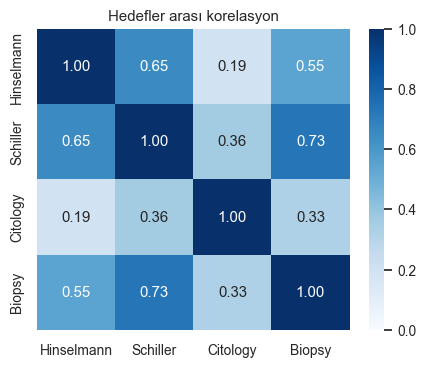

Biyopsi pozitif olanlarda diğer testler de pozitif:
  Hinselmann  25 / 55
  Schiller    48 / 55
  Citology    18 / 55


In [20]:
tgt = pd.DataFrame({"pozitif": df[TARGETS].sum(), "oran_%": (df[TARGETS].mean() * 100).round(1)})
display(tgt)

fig, ax = plt.subplots(figsize=(4.5, 3.8))
sns.heatmap(df[TARGETS].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Hedefler arası korelasyon")
plt.tight_layout()
plt.savefig(FIG / "01_hedef_korelasyon.png", dpi=150)
plt.show()

print("Biyopsi pozitif olanlarda diğer testler de pozitif:")
for t in ["Hinselmann", "Schiller", "Citology"]:
    print(f"  {t:<11} {int((df[t] & df['Biopsy']).sum())} / {int(df['Biopsy'].sum())}")

**Hedef seçimi: `Biopsy`**
- Biyopsi, serviks kanseri/öncül lezyon tanısında **altın standart** (doku örneğinin patolojik incelemesi). Hinselmann (kolposkopi), Schiller (iyot testi) ve sitoloji (Pap smear) tarama testleri.
- Pozitif oran %6.4 (55 hasta): az ama Hinselmann'dan (35) fazla.

**Veri sızıntısı uyarısı:** Hinselmann, Schiller ve Citology biyopsiyle aynı muayene sürecinde elde edilen test sonuçları. Biyopsi pozitif olan 55 hastanın 48'inde Schiller de pozitif. Bunları girdi olarak kullanırsak model "risk faktörlerinden tahmin" yapmaz, sonucu diğer testlerden kopyalar. → **Bu üç sütun girdi olarak kullanılmayacak.**

## 9. Özet: her sütun için ön işleme kararı

Aşağıdaki tablo 03'teki `Pipeline`'ın yol haritası.

In [21]:
decisions = {
    # Demografi
    "Age":                              ("TUT", "Eksik yok. Uç değerler klinik olarak mümkün."),
    "Number of sexual partners":        ("TUT + impute", "26 eksik."),
    "First sexual intercourse":         ("TUT + impute", "7 eksik; yaştan büyük 2 değer → NaN."),
    "Num of pregnancies":               ("TUT + impute", "56 eksik; eksiklerde biyopsi+ oranı yüksek."),
    # Sigara
    "Smokes":                           ("ÇIKAR (türetilmiş)", "Smokes (years) > 0 ile birebir aynı."),
    "Smokes (years)":                   ("TUT + impute", "13 eksik. Sağa çarpık."),
    "Smokes (packs/year)":              ("TUT + impute", "13 eksik. Sağa çarpık; bazı değerler 'yıl' ile aynı (şüpheli)."),
    # Hormonal kontraseptif
    "Hormonal Contraceptives":          ("ÇIKAR (türetilmiş)", "HC (years) > 0 ile birebir aynı."),
    "Hormonal Contraceptives (years)":  ("TUT + impute + gösterge", "108 eksik; eksiklerde biyopsi+ = 0."),
    # RİA
    "IUD":                              ("ÇIKAR (türetilmiş)", "IUD (years) > 0 ile birebir aynı."),
    "IUD (years)":                      ("TUT + impute + gösterge", "117 eksik."),
    # CYBH
    "STDs":                             ("ÇIKAR (türetilmiş)", "STDs (number) > 0 ile birebir aynı."),
    "STDs (number)":                    ("TUT + impute + gösterge", "105 eksik (blok halinde)."),
    "STDs:condylomatosis":              ("TUT + impute", "44 pozitif."),
    "STDs:cervical condylomatosis":     ("ÇIKAR (sabit)", "Hiç pozitif yok."),
    "STDs:vaginal condylomatosis":      ("ÇIKAR (çok nadir)", "4 pozitif."),
    "STDs:vulvo-perineal condylomatosis": ("ÇIKAR (tekrar)", "condylomatosis ile r ≈ 0.99."),
    "STDs:syphilis":                    ("TUT + impute", "18 pozitif."),
    "STDs:pelvic inflammatory disease": ("ÇIKAR (çok nadir)", "1 pozitif."),
    "STDs:genital herpes":              ("ÇIKAR (çok nadir)", "1 pozitif."),
    "STDs:molluscum contagiosum":       ("ÇIKAR (çok nadir)", "1 pozitif."),
    "STDs:AIDS":                        ("ÇIKAR (sabit)", "Hiç pozitif yok."),
    "STDs:HIV":                         ("TUT + impute", "18 pozitif."),
    "STDs:Hepatitis B":                 ("ÇIKAR (çok nadir)", "1 pozitif."),
    "STDs:HPV":                         ("ÇIKAR (çok nadir)", "2 pozitif; HPV bilgisi Dx:HPV'de daha dolu."),
    "STDs: Number of diagnosis":        ("ÇIKAR (gizli eksik)", "CYBH cevapsızlarda 0 yazılmış; STDs (number) ile örtüşüyor."),
    "STDs: Time since first diagnosis": ("ÇIKAR (yapısal eksik)", "%92 tanımsız; yalnızca 71 hastada anlamlı."),
    "STDs: Time since last diagnosis":  ("ÇIKAR (yapısal eksik)", "%92 tanımsız; first ile r ≈ 0.93."),
    # Dx
    "Dx:Cancer":                        ("TUT", "18 pozitif. Dx:HPV ile büyük örtüşme (yorumda dikkat)."),
    "Dx:CIN":                           ("TUT", "9 pozitif."),
    "Dx:HPV":                           ("TUT", "18 pozitif."),
    "Dx":                               ("ÇIKAR (türetilmiş + tutarsız)", "Alt sütunların 'veya'sı; 5 satırda tutarsız."),
    # Hedefler
    "Hinselmann":                       ("ÇIKAR (sızıntı)", "Aynı muayenenin test sonucu."),
    "Schiller":                         ("ÇIKAR (sızıntı)", "Aynı muayenenin test sonucu."),
    "Citology":                         ("ÇIKAR (sızıntı)", "Aynı muayenenin test sonucu."),
    "Biopsy":                           ("HEDEF", "Altın standart; 55 pozitif (%6.4)."),
}
assert set(decisions) == set(df.columns)

dec = pd.DataFrame([{"sütun": c, "grup": group_of[c], "eksik": int(df[c].isna().sum()),
                     "karar": decisions[c][0], "gerekçe": decisions[c][1]} for c in df.columns])
dec.to_csv(TAB / "oznitelik_kararlari.csv", index=False, encoding="utf-8-sig")

print(dec["karar"].str.split(" ").str[0].value_counts().to_string())
dec

karar
ÇIKAR    20
TUT      15
HEDEF     1


,sütun,grup,eksik,karar,gerekçe
0,Age,Demografi / cinsel öykü,0,TUT,Eksik yok. Uç değerler klinik olarak mümkün.
1,Number of sexual partners,Demografi / cinsel öykü,26,TUT + impute,26 eksik.
2,First sexual intercourse,Demografi / cinsel öykü,7,TUT + impute,7 eksik; yaştan büyük 2 değer → NaN.
3,Num of pregnancies,Demografi / cinsel öykü,56,TUT + impute,56 eksik; eksiklerde biyopsi+ oranı yüksek.
4,Smokes,Sigara,13,ÇIKAR (türetilmiş),Smokes (years) > 0 ile birebir aynı.
5,Smokes (years),Sigara,13,TUT + impute,13 eksik. Sağa çarpık.
6,Smokes (packs/year),Sigara,13,TUT + impute,13 eksik. Sağa çarpık; bazı değerler 'yıl' ile...
7,Hormonal Contraceptives,Hormonal kontraseptif,108,ÇIKAR (türetilmiş),HC (years) > 0 ile birebir aynı.
8,Hormonal Contraceptives (years),Hormonal kontraseptif,108,TUT + impute + gösterge,108 eksik; eksiklerde biyopsi+ = 0.
9,IUD,RİA (IUD),117,ÇIKAR (türetilmiş),IUD (years) > 0 ile birebir aynı.


In [22]:
keep = dec.loc[dec["karar"].str.startswith("TUT"), "sütun"].tolist()
print(f"Modelde kullanılacak öznitelik sayısı: {len(keep)}  (36 sütundan; 1 hedef + {36 - 1 - len(keep)} çıkarılan)")
print(keep)

Modelde kullanılacak öznitelik sayısı: 15  (36 sütundan; 1 hedef + 20 çıkarılan)
['Age', 'Number of sexual partners', 'First sexual intercourse', 'Num of pregnancies', 'Smokes (years)', 'Smokes (packs/year)', 'Hormonal Contraceptives (years)', 'IUD (years)', 'STDs (number)', 'STDs:condylomatosis', 'STDs:syphilis', 'STDs:HIV', 'Dx:Cancer', 'Dx:CIN', 'Dx:HPV']


## 10. Sonraki adımlar

| Bulgu | Nerede ele alınacak |
|---|---|
| Eksiklik blok halinde ve hedefle ilişkili görünüyor | **02** · MCAR testi, eksiklik ↔ hedef ilişkisinin istatistiksel testi, MAR/MNAR tartışması |
| Gizli eksik (`Number of diagnosis`), tutarsız yaş | **03** · Pipeline'ın ilk adımı (temizleme) |
| İmputasyon + eksiklik göstergesi | **03** · `SimpleImputer(add_indicator=True)` ile ve onsuz karşılaştırma |
| %6.4 pozitif oran | **04** · Katmanlı CV, PR-AUC, kalibrasyon, bootstrap GA |
| Tekrar eden 23 satır | **04** · Duyarlılık analizi (opsiyonel) |